In [0]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay



In [0]:
df = pd.read_csv('/Volumes/workspace/bronze/student_dep/Student_Depression_Dataset.csv')

df.head(10)

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes
5,Female,24,Middle class,Single,Unmarried,Bachelor,9,3.80,Yes,Normal,17244,Chittagong,No
6,Female,21,Lower Middle class,Single,Unmarried,Family,9,3.50,Yes,Normal,1648,Dhaka,No
7,Female,19,Middle class,Single,Unmarried,Family,2,2.71,Yes,Abnormal,16782,Rajshahi,Yes
8,Female,21,Middle class,Single,Unmarried,Family,3,3.10,Yes,Abnormal,13386,Dhaka,Yes
9,Female,22,Middle class,In a Relationship,Married,Family,4,3.34,Yes,Normal,18131,Mymensingh,No


In [0]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   object 
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   object 
 3   Relationship_status  4464 non-null   object 
 4   Marital_status       4464 non-null   object 
 5   Living_style         4464 non-null   object 
 6   Current_semester     4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   object 
 9   Health_condition     4464 non-null   object 
 10  Cost_without_study   4464 non-null   int64  
 11  Home_division        4464 non-null   object 
 12  Depression           4464 non-null   object 
dtypes: float64(1), int64(3), object(9)
memory usage: 453.5+ KB


In [0]:
df.describe()

,Age,Current_semester,CGPA,Cost_without_study
count,4464.000000,4464.000000,4464.000000,4464.000000
mean,22.619176,5.401210,3.412753,11242.978271
std,2.022980,2.578476,0.385605,6640.144019
min,17.000000,0.000000,2.250000,0.000000
25%,21.000000,3.000000,3.150000,6100.000000
50%,23.000000,5.000000,3.490000,9500.000000
75%,24.000000,7.000000,3.700000,15439.000000
max,28.000000,13.000000,4.000000,32000.000000


{'whiskers': [<matplotlib.lines.Line2D at 0xffef0a286ba0>,
 'caps': [<matplotlib.lines.Line2D at 0xffef0a225880>,
 'boxes': [<matplotlib.lines.Line2D at 0xffef0a2865a0>],
 'medians': [<matplotlib.lines.Line2D at 0xffef0a2277a0>],
 'fliers': [<matplotlib.lines.Line2D at 0xffef0a2270b0>],
 'means': []}

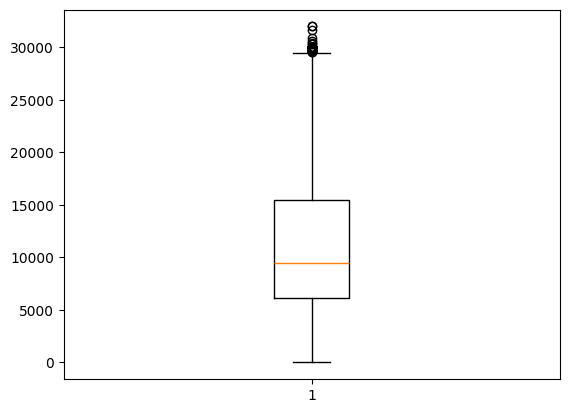

In [0]:
plt.boxplot(df['Cost_without_study'])

In [0]:
#Tratando variáveis binárias

df['Gender'] = df['Gender'].map({'Female': 0, 'Male': 1})
df.Gender.astype('int64')

df['Living_style'] = df['Living_style'].map({'Bachelor': 0, 'Family': 1})
df.Living_style.astype('int64')

df['friend_circle'] = df['friend_circle'].map({'No': 0, 'Yes':1})
df.friend_circle.astype('int64')

df['Depression'] = df['Depression'].map({'No': 0, 'Yes': 1})
df.Depression.astype('int64')

0       1
1       1
2       1
3       0
4       1
       ..
4459    1
4460    1
4461    0
4462    0
4463    1
Name: Depression, Length: 4464, dtype: int64

In [0]:
#Tratando variáveis categóricas

cat_df = df[['Relationship_status', 'Marital_status', 'Home_division']]
encoder = OneHotEncoder(dtype=np.int64)
cat_df = encoder.fit_transform(cat_df)
cat_df = pd.DataFrame(cat_df.toarray(), columns=encoder.get_feature_names_out())

df.drop(['Relationship_status', 'Marital_status', 'Home_division'], axis=1, inplace=True)

df = pd.concat([df, cat_df], axis=1)

In [0]:
#Categóricas ordinais
ordinal_cols = df[['Family_background', 'Health_condition']]

ord_enc = OrdinalEncoder(categories=[
    ['Lower Middle class', 'Middle class', 'Rich class'],
    ['Normal', 'Good', 'Critical', 'Abnormal']
], dtype=np.int64)

df_ord = ord_enc.fit_transform(ordinal_cols)
df_ord = pd.DataFrame(df_ord, columns=ord_enc.get_feature_names_out())

df.drop(['Family_background', 'Health_condition'], axis=1, inplace=True)

df = pd.concat([df, df_ord], axis=1)

In [0]:
df.head()

,Gender,Age,Living_style,Current_semester,CGPA,friend_circle,Cost_without_study,Depression,Relationship_status_Complicated,Relationship_status_In a Relationship,Relationship_status_Single,Marital_status_Married,Marital_status_Separated,Marital_status_Unmarried,Home_division_Barisal,Home_division_Chittagong,Home_division_Dhaka,Home_division_Khulna,Home_division_Mymensingh,Home_division_Rajshahi,Home_division_Rangpur,Home_division_Sylhet,Family_background,Health_condition
0,0,22,0,8,3.43,1,10113,1,0,0,1,0,0,1,0,1,0,0,0,0,0,0,1,2
1,1,19,0,2,3.70,1,13815,1,0,0,1,0,0,1,0,1,0,0,0,0,0,0,1,3
2,1,23,1,8,3.28,0,15450,1,0,0,1,0,0,1,0,0,1,0,0,0,0,0,1,3
3,1,20,1,2,3.77,0,17413,0,1,0,0,0,0,1,0,0,1,0,0,0,0,0,1,1
4,0,21,1,1,4.00,0,16693,1,0,0,1,0,0,1,0,0,1,0,0,0,0,0,1,3


In [0]:
X = df.drop('Depression', axis=1)
y = df['Depression']

In [0]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=10
)

In [0]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=10
)

In [0]:
model = XGBClassifier(
    random_state=10
)

model.fit(    
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    )

[0]	validation_0-logloss:0.34959
[1]	validation_0-logloss:0.25127
[2]	validation_0-logloss:0.18937
[3]	validation_0-logloss:0.14632
[4]	validation_0-logloss:0.11532
[5]	validation_0-logloss:0.09358
[6]	validation_0-logloss:0.07773
[7]	validation_0-logloss:0.06649
[8]	validation_0-logloss:0.05828
[9]	validation_0-logloss:0.05241
[10]	validation_0-logloss:0.04703
[11]	validation_0-logloss:0.04416
[12]	validation_0-logloss:0.04064
[13]	validation_0-logloss:0.03848
[14]	validation_0-logloss:0.03686
[15]	validation_0-logloss:0.03499
[16]	validation_0-logloss:0.03358
[17]	validation_0-logloss:0.03226
[18]	validation_0-logloss:0.03150
[19]	validation_0-logloss:0.03041
[20]	validation_0-logloss:0.02998
[21]	validation_0-logloss:0.02971
[22]	validation_0-logloss:0.02931
[23]	validation_0-logloss:0.02989
[24]	validation_0-logloss:0.02945
[25]	validation_0-logloss:0.02917
[26]	validation_0-logloss:0.02843
[27]	validation_0-logloss:0.02833
[28]	validation_0-logloss:0.02813
[29]	validation_0-loglos

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,None


In [0]:
y_pred = model.predict(X_val)

print(classification_report(y_val, y_pred))

              precision    recall  f1-score   support

           0       0.99      1.00      0.99       497
           1       0.99      0.97      0.98       173

    accuracy                           0.99       670
   macro avg       0.99      0.98      0.98       670
weighted avg       0.99      0.99      0.99       670



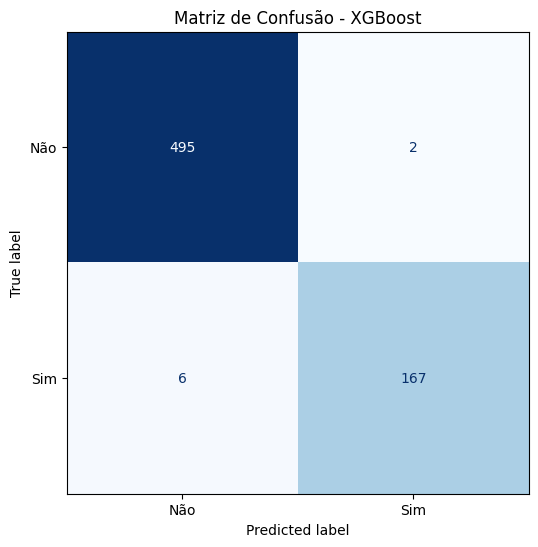

In [0]:
cm = confusion_matrix(y_val, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Não', 'Sim']
)

fig, ax = plt.subplots(figsize=(8, 6))

disp.plot(
    cmap='Blues',
    ax=ax,
    colorbar=False
)

ax.set_title('Matriz de Confusão - XGBoost')

plt.show()

In [0]:
estudante = X_test.iloc[[0]]

predicao = model.predict(estudante)

print('Classe prevista:', predicao[0])
print('Classe real:', y_test.iloc[0])

Classe prevista: 0
Classe real: 0
